# SAYA: three AI algorithms, one goal

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Akanov-Kanta/saya/blob/main/SAYA_algorithms.ipynb)

**Goal.** A wheelchair user or an elderly pedestrian wants to walk from Astana IT University to Mega Silk Way on a hot July afternoon. SAYA finds a route they can actually pass and decides whether a shadier detour is worth it today.

| # | Algorithm | Course group | Question it answers | What it passes on |
|---|---|---|---|---|
| 1 | **A\* search** | Search | Which routes can this person pass, and how much of each is in the sun? | two routes: *Shortest* and *Shaded* |
| 2 | **Bayesian inference** | Probabilistic reasoning | Is it dangerously hot right now? | P(Dangerous heat) |
| 3 | **MDP**, one Bellman update | Decisions under uncertainty | Shortest or Shaded? | the recommended route |

```
OpenStreetMap + sun position -> shade on every path -> 1. A*    -> two routes ----\
Open-Meteo "feels like"      ----------------------> 2. Bayes -> P(Dangerous) --> 3. MDP -> decision
```

The three algorithms are **written out in this notebook**. Loading the map, the sun position and the shadow geometry come from the project files ([github.com/Akanov-Kanta/saya](https://github.com/Akanov-Kanta/saya)). The last section checks that the notebook code gives exactly the same numbers as the project code.

**Run it:** *Runtime → Run all*. The first cell downloads the project and installs `osmnx` (about a minute). The map data and the weather readings are saved in the repo, so nothing else is downloaded.

In [1]:
# Setup. In Colab: download the project and install osmnx. Locally: run this notebook from the repo root.
import os, subprocess, sys

if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != "saya":
    if not os.path.exists("saya"):
        subprocess.run(["git", "clone", "-q", "https://github.com/Akanov-Kanta/saya.git"], check=True)
    os.chdir("saya")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "osmnx>=2.0,<3"], check=True)
sys.path.insert(0, os.getcwd())

import heapq, itertools, math
from datetime import datetime

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display

import config, osm_data, planner, weather
from osm_data import first          # reads an OSM tag that may be a list or missing
from sun import compass

pd.set_option("display.precision", 3)
print("Ready")

Ready


## 0. The map, the sun and the shade

The study area is a 700 m circle between AITU and Mega Silk Way (EXPO district). From OpenStreetMap we take:

- the **walk network**: nodes are intersections and path vertices, edges are path segments with their length and tags (road type, surface, crossing);
- **buildings** with heights (`height` tag, or `building:levels × 3.2 m`, or 9 m by default);
- **trees** (each one shades 3 m around itself).

Two places have **simulated** resident reports of barriers (a broken kerb ramp and steps without a ramp). OSM has no kerb or step data for this area.

In [2]:
graph, buildings, trees, barriers = osm_data.load_area()      # saved in data/, no internet needed
area = planner.Area(graph, buildings, trees, barriers)        # projects to metres (UTM 42N), marks barriers

print(f"Walk network: {graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges")
print(f"{len(buildings)} buildings, {len(trees)} trees / tree rows")
for b in area.barriers:
    print(f"Barrier report (simulated): {b['name']} [{b['type']}] -> {b['edges_marked']} edges")

Walk network: 1593 nodes, 4840 edges
204 buildings, 45 trees / tree rows
Barrier report (simulated): Broken kerb ramp at the crossing to Mega Silk Way [broken_ramp] -> 8 edges
Barrier report (simulated): Steps without a ramp on the path by EXPO C1 [steps] -> 6 edges


**Sun and shadows.** `sun.py` computes the sun's altitude and azimuth with NOAA's solar position formulas. A building of height $h$ casts a shadow of length

$$\text{shadow} = \frac{h}{\tan(\text{altitude})}$$

pointing away from the sun (azimuth + 180°). `shade.py` sweeps every footprint along that vector and joins all shadows. Then every path edge gets a **sun fraction** between 0 (fully shaded) and 1 (fully in the sun). This is the input to A*.

In [3]:
AITU = config.PLACES["aitu"][1:]          # (lat, lon)
MEGA = config.PLACES["megasilkway"][1:]
WHEN = datetime(2026, 7, 15, 16, 0, tzinfo=config.ASTANA_TZ)   # a hot July afternoon, Astana time

network = area.set_time(WHEN)             # writes sun_fraction onto every edge of the graph
alt, az = network.altitude, network.azimuth
print(f"{WHEN:%d %B %Y, %H:%M}: sun altitude {alt:.1f} deg, azimuth {az:.0f} deg ({compass(az)})")
print(f"A 10 m building casts a {10 / math.tan(math.radians(alt)):.1f} m shadow towards {compass(az + 180)}")
print(f"Shade covers {network.shaded_share:.0%} of all path length at this moment")

15 July 2026, 16:00: sun altitude 38.5 deg, azimuth 256 deg (W)
A 10 m building casts a 12.6 m shadow towards E
Shade covers 8% of all path length at this moment


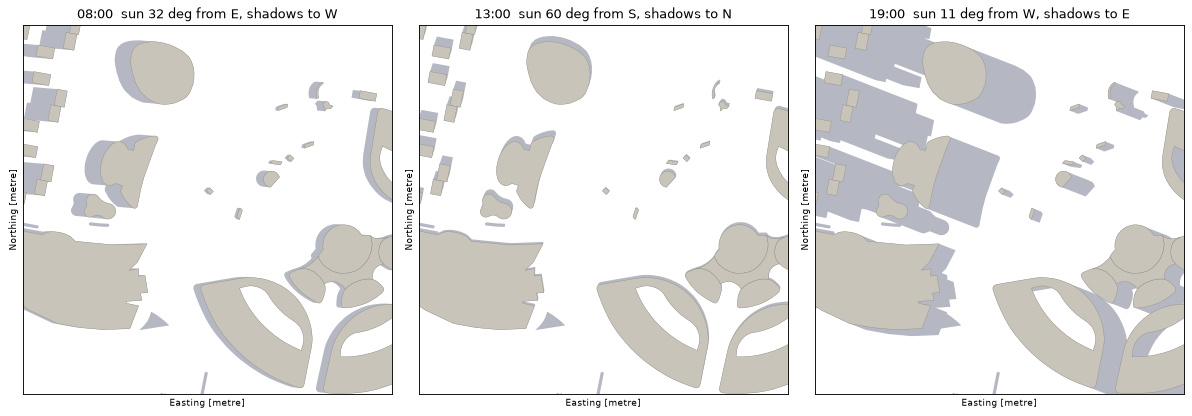

In [4]:
CENTER = planner.to_metres(*config.AREA_CENTER)

def draw_base(ax, when, radius=650, title=None):
    # Shadows (dark), buildings (grey) and the walk network for one moment
    shade_geometry = area.shade_at(when)[2]
    if not shade_geometry.is_empty:
        gpd.GeoSeries([shade_geometry], crs=config.PROJECTED_CRS).plot(ax=ax, color="#2b3150", alpha=0.35, linewidth=0)
    area.buildings_m.plot(ax=ax, color="#c9c4ba", edgecolor="#8c877d", linewidth=0.3)
    ax.set_xlim(CENTER.x - radius, CENTER.x + radius)
    ax.set_ylim(CENTER.y - radius, CENTER.y + radius)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title or f"{when:%H:%M}")

# The same blocks at three times of day: shadows rotate and stretch with the sun
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=80)
for ax, hour in zip(axes, (8, 13, 19)):
    when = WHEN.replace(hour=hour)
    a, z, *_ = area.shade_at(when)
    draw_base(ax, when, radius=350, title=f"{hour:02d}:00  sun {a:.0f} deg from {compass(z)}, shadows to {compass(z + 180)}")
plt.tight_layout(); plt.show()

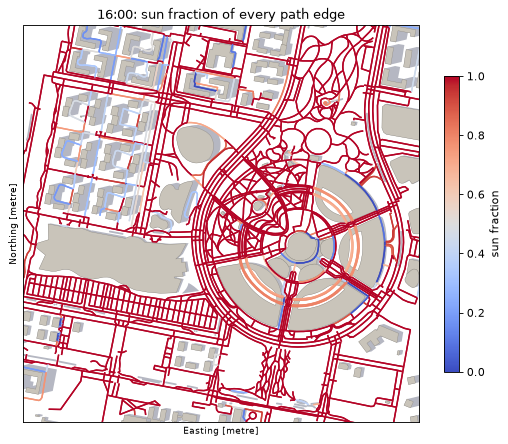

In [5]:
# Every path edge coloured by its sun fraction at 16:00 (blue = shade, red = full sun)
sun_fraction = area.shade_at(WHEN)[3]
fig, ax = plt.subplots(figsize=(8, 8), dpi=80)
draw_base(ax, WHEN, title="16:00: sun fraction of every path edge")
area.edges.assign(sun=sun_fraction).plot(ax=ax, column="sun", cmap="coolwarm", vmin=0, vmax=1, linewidth=1.3,
                                         legend=True, legend_kwds={"shrink": 0.6, "label": "sun fraction"})
plt.show()

## 1. A\* search: routes this person can actually pass

**The search problem**

| | |
|---|---|
| State | a node of the walk network |
| Actions | walk along an edge to a neighbouring node |
| Start, goal | the nodes nearest to AITU and to Mega Silk Way |
| Step cost | $\text{cost} = \text{length} \times \text{access}(\text{profile}) \times (1 + w \cdot \text{sun\_fraction}) + \text{crossing\_extra}$ |
| Heuristic | $h(n)$ = straight-line distance from $n$ to the goal, in metres |

- **access(profile)** makes edges harder or impossible for the walker: steps and a broken ramp are impassable for a wheelchair, roads without a sidewalk and paving stones cost extra, and a crossing without a traffic light adds extra metres.
- **w** is the sun weight. $w = 0$ gives the **Shortest** accessible route. $w = 3$ gives the **Shaded** route, where 1 m in the sun counts as 4 m.

**Why A\* is optimal here.** All multipliers are ≥ 1 and the extras are ≥ 0, so every edge costs at least its length, and its length is at least the straight-line distance between its ends. So the remaining cost from any node is at least the straight line to the goal: $h$ never overestimates (admissible). It also satisfies $h(n) \le c(n, n') + h(n')$ (consistent), so every node is expanded at most once.

The mobility profiles (all values are assumptions from `config.py`):

In [6]:
def show(value, prefix="x"):
    return "impassable" if value is None else f"{prefix}{value}"

pd.DataFrame({
    p["label"]: {
        "speed, m/s": p["speed_mps"],
        "heat vulnerability": p["heat_vulnerability"],
        "road without sidewalk": show(p["road_no_sidewalk"]),
        "busy road": show(p["busy_road"]),
        "paving stones": show(p["paving_stones"]),
        "crossing without light": f"+{p['uncontrolled_crossing_m']} m",
        "steps": show(p["barrier"]["steps"]),
        "broken ramp": show(p["barrier"]["broken_ramp"]),
    }
    for p in config.PROFILES.values()
})

,Wheelchair user,Elderly pedestrian,Pedestrian without mobility needs
"speed, m/s",0.9,1.0,1.3
heat vulnerability,1.5,1.8,1.0
road without sidewalk,x1.6,x1.4,x1.1
busy road,x3.0,x2.0,x1.2
paving stones,x1.2,x1.05,x1.0
crossing without light,+60 m,+40 m,+0 m
steps,impassable,x3.0,x1.0
broken ramp,impassable,x1.0,x1.0


### The edge cost

In [7]:
ROUGH_SURFACES = {"paving_stones", "sett", "cobblestone", "unhewn_cobblestone", "gravel", "fine_gravel", "compacted"}

def is_uncontrolled_crossing(graph, u, v, data):
    # A pedestrian crossing with no traffic light on the way or on its end nodes
    if first(data.get("footway")) != "crossing" and first(data.get("highway")) != "crossing":
        return False
    tags = [first(data.get("crossing"))]
    for node in (u, v):
        tags += [first(graph.nodes[node].get("crossing")), first(graph.nodes[node].get("highway"))]
    return "traffic_signals" not in tags

def access(graph, u, v, data, profile):
    # How hard is this edge for this person? (multiplier >= 1, extra metres >= 0), or None if impassable
    multiplier, extra = 1.0, 0.0
    highway = first(data.get("highway"))
    barrier = data.get("barrier_type") or ("steps" if highway == "steps" else None)
    if barrier:
        factor = profile["barrier"].get(barrier, 1.0)
        if factor is None:
            return None                                   # e.g. steps for a wheelchair
        multiplier *= factor
    if highway in config.BUSY_ROADS:
        multiplier *= profile["busy_road"]
    elif highway not in config.FOOT_HIGHWAYS and highway != "steps":
        multiplier *= profile["road_no_sidewalk"]
    if first(data.get("surface")) in ROUGH_SURFACES:
        multiplier *= profile["paving_stones"]
    if is_uncontrolled_crossing(graph, u, v, data):
        extra += profile["uncontrolled_crossing_m"]
    return multiplier, extra

def make_edge_cost(graph, profile, w):
    # cost = length * access * (1 + w * sun_fraction) + extra metres
    def edge_cost(u, v, key, data):
        result = access(graph, u, v, data, profile)
        if result is None:
            return None
        multiplier, extra = result
        return data["length"] * multiplier * (1 + w * data.get("sun_fraction", 0.0)) + extra
    return edge_cost

### A\* itself

The frontier is a priority queue ordered by $f(n) = g(n) + h(n)$, where $g(n)$ is the cheapest known cost from the start. With `use_heuristic=False` we get $h = 0$, which is exactly Dijkstra (uniform-cost search). We run it only to compare how many nodes each one expands.

In [8]:
def astar(graph, start, goal, edge_cost, use_heuristic=True, trace=None):
    goal_x, goal_y = graph.nodes[goal]["x"], graph.nodes[goal]["y"]

    def h(node):                                           # straight-line distance to the goal
        if not use_heuristic:
            return 0.0
        return math.hypot(graph.nodes[node]["x"] - goal_x, graph.nodes[node]["y"] - goal_y)

    tie = itertools.count()                                # breaks ties without comparing nodes
    frontier = [(h(start), next(tie), start)]              # (f, tie, node)
    g = {start: 0.0}
    came_from = {start: None}                              # node -> (previous node, edge key)
    closed = set()

    while frontier:
        f, _, node = heapq.heappop(frontier)               # the node with the smallest f
        if node in closed:
            continue                                       # stale entry: a cheaper one was expanded already
        closed.add(node)
        if trace is not None:
            trace.append({"expand": node, "g": g[node], "h": h(node), "f = g + h": f})
        if node == goal:
            break
        for neighbour, parallel_edges in graph[node].items():
            # two nodes can be joined by several OSM ways: take the cheapest passable one
            options = [(edge_cost(node, neighbour, key, data), key) for key, data in parallel_edges.items()]
            options = [(cost, key) for cost, key in options if cost is not None]
            if not options:
                continue                                   # impassable for this profile
            step_cost, key = min(options)
            new_g = g[node] + step_cost
            if new_g < g.get(neighbour, math.inf):         # found a cheaper way to the neighbour
                g[neighbour] = new_g
                came_from[neighbour] = (node, key)
                heapq.heappush(frontier, (new_g + h(neighbour), next(tie), neighbour))

    if goal not in closed:
        return {"found": False, "path": [], "edges": [], "cost": math.inf, "expanded": len(closed)}
    path, edges, node = [goal], [], goal                   # walk back from the goal
    while came_from[node] is not None:
        previous, key = came_from[node]
        edges.append((previous, node, key))
        path.append(previous)
        node = previous
    return {"found": True, "path": path[::-1], "edges": edges[::-1], "cost": g[goal], "expanded": len(closed)}


def route_stats(graph, result, profile):
    # Length, metres and minutes in the sun, crossings and barriers of a found route
    length = sun = 0.0
    crossings = 0
    for u, v, key in result["edges"]:
        data = graph.edges[u, v, key]
        length += data["length"]
        sun += data["length"] * data.get("sun_fraction", 0.0)
        crossings += is_uncontrolled_crossing(graph, u, v, data)
    speed = profile["speed_mps"]
    return {"length_m": length, "sun_m": sun, "sun_share": sun / length if length else 0.0,
            "walk_min": length / speed / 60, "sun_min": sun / speed / 60,
            "uncontrolled_crossings": crossings, "cost": result["cost"], "expanded": result["expanded"]}

### 1a. A\* by hand on a toy map

Two streets from A to D. The bottom one is shorter but in full sun. The top one is longer but shaded.

```
          C            top street: 2 x 116.6 m, sun_fraction 0 (shaded)
        /   \
      A ----- B ----- D
          bottom street: 2 x 100 m, sun_fraction 1 (full sun)
```

In [9]:
toy = nx.MultiDiGraph()
for name, (x, y) in {"A": (0, 0), "B": (100, 0), "C": (100, 60), "D": (200, 0)}.items():
    toy.add_node(name, x=x, y=y)

def street(u, v, sun_fraction):
    length = math.dist((toy.nodes[u]["x"], toy.nodes[u]["y"]), (toy.nodes[v]["x"], toy.nodes[v]["y"]))
    for a, b in ((u, v), (v, u)):                          # both directions
        toy.add_edge(a, b, length=length, sun_fraction=sun_fraction, highway="footway")

street("A", "B", 1.0); street("B", "D", 1.0)               # sunny street
street("A", "C", 0.0); street("C", "D", 0.0)               # shaded street

wheelchair = config.PROFILES["wheelchair"]
for w in (0, 3):
    trace = []
    result = astar(toy, "A", "D", make_edge_cost(toy, wheelchair, w), trace=trace)
    print(f"w = {w}: path {' -> '.join(result['path'])}, cost {result['cost']:.1f}, expanded {result['expanded']} nodes")
    display(pd.DataFrame(trace))

w = 0: path A -> B -> D, cost 200.0, expanded 3 nodes


,expand,g,h,f = g + h
0,A,0.0,200.0,200.0
1,B,100.0,100.0,200.0
2,D,200.0,0.0,200.0


w = 3: path A -> C -> D, cost 233.2, expanded 3 nodes


,expand,g,h,f = g + h
0,A,0.000,200.000,200.000
1,C,116.619,116.619,233.238
2,D,233.238,0.000,233.238


With $w = 0$ the sunny street costs 200 and wins. With $w = 3$ each sunny metre counts as 4, so the sunny street costs 800 and the shaded one 233.2. A\* never even expands B: its $f = 400 + 100 = 500$ is larger than the cost of the goal.

**Accessibility.** Now put a broken kerb ramp on the shaded street (C to D):

In [10]:
for u, v in (("C", "D"), ("D", "C")):
    toy.edges[u, v, 0]["barrier_type"] = "broken_ramp"

for key in ("wheelchair", "standard"):
    result = astar(toy, "A", "D", make_edge_cost(toy, config.PROFILES[key], 3))
    print(f"{config.PROFILES[key]['label']:<34} w = 3: {' -> '.join(result['path'])}")

Wheelchair user                    w = 3: A -> B -> D
Pedestrian without mobility needs  w = 3: A -> C -> D


The broken ramp is impassable for the wheelchair user, so A\* sends them back into the sun. The pedestrian without mobility needs still takes the shaded street.

### 1b. A\* on the real map: AITU → Mega Silk Way, wheelchair user, 16:00

In [11]:
PROFILE = config.PROFILES["wheelchair"]
G = network.graph                                          # projected graph, sun_fraction for 16:00
start, _ = area.nearest_node(*AITU)
goal, _ = area.nearest_node(*MEGA)

routes, results, table = {}, {}, {}
for action, w in (("Shortest", config.SUN_WEIGHT["shortest"]), ("Shaded", config.SUN_WEIGHT["shaded"])):
    cost = make_edge_cost(G, PROFILE, w)
    result = astar(G, start, goal, cost)
    dijkstra = astar(G, start, goal, cost, use_heuristic=False)
    assert math.isclose(result["cost"], dijkstra["cost"])     # A* finds the same optimal cost as Dijkstra
    results[action], routes[action] = result, route_stats(G, result, PROFILE)
    s = routes[action]
    table[action] = {"w": w, "length, m": round(s["length_m"]), "in sun": f"{s['sun_share']:.0%}",
                     "minutes": round(s["walk_min"], 1), "sun minutes": round(s["sun_min"], 1),
                     "A* expanded": result["expanded"], "Dijkstra expanded": dijkstra["expanded"]}
display(pd.DataFrame(table).T)

extra_m = routes["Shaded"]["length_m"] - routes["Shortest"]["length_m"]
less_sun = routes["Shortest"]["sun_m"] - routes["Shaded"]["sun_m"]
print(f"The shaded route is {extra_m:+.0f} m and {routes['Shaded']['walk_min'] - routes['Shortest']['walk_min']:+.1f} min, "
      f"with {less_sun:.0f} m less walking in the sun.")

,w,"length, m",in sun,minutes,sun minutes,A* expanded,Dijkstra expanded
Shortest,0.0,1560,100%,28.9,28.8,878,1367
Shaded,3.0,1657,81%,30.7,24.7,1269,1381


The shaded route is +97 m and +1.8 min, with 221 m less walking in the sun.


In [12]:
# Check the admissibility argument on every edge of the real map
cost_w0 = make_edge_cost(G, PROFILE, 0)
ratios = []
for u, v, key, data in G.edges(keys=True, data=True):
    c = cost_w0(u, v, key, data)
    straight = math.hypot(G.nodes[u]["x"] - G.nodes[v]["x"], G.nodes[u]["y"] - G.nodes[v]["y"])
    if c is not None and straight > 0:
        ratios.append(c / straight)
assert min(ratios) >= 1 - 1e-9
print(f"Smallest edge cost / straight-line distance over {len(ratios)} edges: {min(ratios):.4f}")
print("No edge is cheaper than a straight line, so h(n) never overestimates.")

Smallest edge cost / straight-line distance over 4822 edges: 1.0000
No edge is cheaper than a straight line, so h(n) never overestimates.


A detail that matters for this proof: the edge lengths and the heuristic must be measured the same way. osmnx measures lengths on a sphere, and at Astana's latitude those are up to 0.3 % shorter than metres in the UTM projection that $h$ uses. That would let $h$ overestimate slightly. So `planner.Area` re-measures every edge in UTM metres, and then the check above holds exactly.

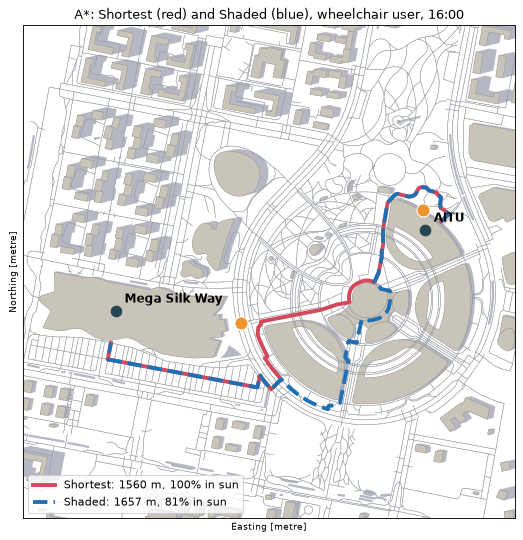

In [13]:
def route_line(edges):
    xs, ys = [], []
    for u, v, key in edges:
        line = area.edges.loc[(u, v, key), "geometry"]
        x, y = line.xy
        xs += list(x); ys += list(y)
    return xs, ys

fig, ax = plt.subplots(figsize=(8, 8), dpi=80)
draw_base(ax, WHEN, title="A*: Shortest (red) and Shaded (blue), wheelchair user, 16:00")
area.edges.plot(ax=ax, color="#9aa0a6", linewidth=0.4)
for action, colour, style in (("Shortest", "#d1495b", "-"), ("Shaded", "#1f6fb2", "--")):
    ax.plot(*route_line(results[action]["edges"]), color=colour, linestyle=style, linewidth=3.5,
            label=f"{action}: {routes[action]['length_m']:.0f} m, {routes[action]['sun_share']:.0%} in sun")
for b in area.barriers:
    p = planner.to_metres(b["lat"], b["lon"])
    ax.scatter(p.x, p.y, s=140, color="#f0932b", edgecolor="white", zorder=5)
for (lat, lon), label in ((AITU, "AITU"), (MEGA, "Mega Silk Way")):
    p = planner.to_metres(lat, lon)
    ax.scatter(p.x, p.y, s=90, color="#264653", zorder=6)
    ax.annotate(label, (p.x, p.y), xytext=(8, 8), textcoords="offset points", fontsize=11, weight="bold")
ax.legend(loc="lower left")
plt.show()

Orange dots are the simulated barrier reports. Both routes avoid them, because for a wheelchair they are impassable.

**What A\* passes on:** two routes with their length, walking minutes and minutes in the sun. On their own they do not say which one to take. That depends on how hot it really is (Bayes) and on how much heat stress costs this person (MDP).

## 2. Bayesian inference: is it dangerously hot right now?

- **Hidden state** $H \in \{\text{Dangerous}, \text{Safe}\}$: is walking in the sun right now dangerous for heat?
- **Prior** $P(\text{Dangerous})$ depends on the month (a summer afternoon in Astana is often, but not always, dangerous).
- **Observation**: the Open-Meteo "feels like" temperature, put in a bucket: *cool* (< 24 °C), *warm* (24 to 30 °C) or *hot* (≥ 30 °C).
- The forecast is a **noisy sensor**, so each reading has a likelihood under each state.

$$P(\text{Dangerous} \mid r) = \frac{P(r \mid \text{Dangerous})\,P(\text{Dangerous})}{P(r \mid \text{Dangerous})\,P(\text{Dangerous}) + P(r \mid \text{Safe})\,P(\text{Safe})}$$

In [14]:
print("Prior P(Dangerous) by month (other months: 0.01)")
display(pd.DataFrame({"P(Dangerous)": config.HEAT_PRIOR_BY_MONTH}).T)
print("Likelihood P(reading | state)")
display(pd.DataFrame(config.HEAT_LIKELIHOOD).T)

Prior P(Dangerous) by month (other months: 0.01)


,6,7,8,5,9
P(Dangerous),0.25,0.3,0.25,0.08,0.08


Likelihood P(reading | state)


,cool,warm,hot
Dangerous,0.05,0.25,0.7
Safe,0.55,0.35,0.1


In [15]:
def prior_for_month(month):
    return config.HEAT_PRIOR_BY_MONTH.get(month, config.HEAT_PRIOR_DEFAULT)

def reading_bucket(feels_like):
    for upper, name in config.FEELS_LIKE_BUCKETS:          # (24, cool), (30, warm), (inf, hot)
        if feels_like < upper:
            return name

def heat_posterior(prior, reading, likelihood=config.HEAT_LIKELIHOOD):
    joint_dangerous = prior * likelihood["Dangerous"][reading]     # P(reading, Dangerous)
    joint_safe = (1 - prior) * likelihood["Safe"][reading]         # P(reading, Safe)
    evidence = joint_dangerous + joint_safe                        # P(reading)
    return {"prior": prior, "reading": reading, "joint_dangerous": joint_dangerous,
            "joint_safe": joint_safe, "evidence": evidence, "posterior": joint_dangerous / evidence}

In [16]:
feels_like, source = weather.feels_like_at(WHEN, *AITU)   # saved in data/weather_cache.json
reading = reading_bucket(feels_like)
belief = heat_posterior(prior_for_month(WHEN.month), reading)
L = config.HEAT_LIKELIHOOD

print(f"Sensor: {source}")
print(f"Reading: feels like {feels_like} degC -> '{reading}'")
print(f"Prior:   P(Dangerous) for month {WHEN.month} = {belief['prior']:.2f}")
print(f"P({reading}) = {belief['prior']:.2f} x {L['Dangerous'][reading]:.2f} + {1 - belief['prior']:.2f} x {L['Safe'][reading]:.2f}"
      f" = {belief['evidence']:.3f}")
print(f"P(Dangerous | {reading}) = {belief['joint_dangerous']:.3f} / {belief['evidence']:.3f} = {belief['posterior']:.3f}")

Sensor: Open-Meteo archive: air 32.7 degC, feels like 31.0 degC (cached)
Reading: feels like 31.0 degC -> 'hot'
Prior:   P(Dangerous) for month 7 = 0.30
P(hot) = 0.30 x 0.70 + 0.70 x 0.10 = 0.280
P(Dangerous | hot) = 0.210 / 0.280 = 0.750


**Why Bayes and not just "if feels-like ≥ 30"?** The same reading means different things in different months. The prior carries what we know about the season, and the likelihood carries how much we trust the forecast:

In [17]:
pd.DataFrame({
    f"{name} (prior {prior_for_month(m):.2f})": {r: heat_posterior(prior_for_month(m), r)["posterior"] for r in ("cool", "warm", "hot")}
    for m, name in ((5, "May"), (7, "July"), (10, "October"))
}).rename_axis("P(Dangerous | reading)").round(3)

,May (prior 0.08),July (prior 0.30),October (prior 0.01)
P(Dangerous | reading),,,
cool,0.008,0.038,0.001
warm,0.058,0.234,0.007
hot,0.378,0.750,0.066


**What Bayes passes on:** $P(\text{Dangerous}) = 0.75$ for this afternoon. The MDP uses it to weigh the heat risk of each route.

## 3. MDP: take the shortest route or the shaded one?

| | |
|---|---|
| States $S$ | Comfortable, HeatStressed (the walker's condition) |
| Actions $A$ | Shortest, Shaded (the two A\* routes) |
| Reward $R(s, a)$ | minus the walking minutes of route $a$ |
| Terminal values $V_0$ | $V_0(\text{Comfortable}) = 0$, $V_0(\text{HeatStressed}) = -60$ (heat stress counts as 60 extra minutes) |
| Discount | $\gamma = 0.9$ |

**Transitions.** Every minute in direct sun is a small chance of becoming heat-stressed: 3 % per minute when the heat is Dangerous, 0.2 % when it is Safe, times the person's heat vulnerability (wheelchair 1.5). We average over the Bayes belief:

$$P(\text{stress} \mid a) = \sum_{x \in \{D, S\}} P(x)\left(1 - (1 - v \cdot \lambda_x)^{\text{sun\_min}(a)}\right)$$

A walker who is already stressed recovers with probability $0.5 \times$ the shaded share of the route.

**One Bellman update:**

$$Q(s, a) = R(s, a) + \gamma \sum_{s'} P(s' \mid s, a)\, V_0(s') \qquad \pi(s) = \arg\max_a Q(s, a)$$

In [18]:
STATES = ("Comfortable", "HeatStressed")
ACTIONS = ("Shortest", "Shaded")
GAMMA = config.MDP_GAMMA
V0 = {"Comfortable": 0.0, "HeatStressed": -config.HEAT_STRESS_PENALTY}

def p_heat_stress(sun_minutes, p_dangerous, vulnerability):
    total = 0.0
    for heat, p_heat in (("Dangerous", p_dangerous), ("Safe", 1 - p_dangerous)):
        hazard = min(vulnerability * config.HAZARD_PER_SUN_MINUTE[heat], 0.99)   # per sun minute
        total += p_heat * (1 - (1 - hazard) ** sun_minutes)                     # P(stressed at least once)
    return total

def build_mdp(routes, p_dangerous, vulnerability):
    P, R = {}, {}
    for a in ACTIONS:
        r = routes[a]
        p_stress = p_heat_stress(r["sun_min"], p_dangerous, vulnerability)
        p_recover = config.RECOVERY_IN_SHADE * (1 - r["sun_share"])
        P["Comfortable", a] = {"Comfortable": 1 - p_stress, "HeatStressed": p_stress}
        P["HeatStressed", a] = {"Comfortable": p_recover, "HeatStressed": 1 - p_recover}
        for s in STATES:
            R[s, a] = -r["walk_min"]
    return P, R

def bellman_update(P, R, V, gamma=GAMMA):
    Q = {(s, a): R[s, a] + gamma * sum(p * V[s2] for s2, p in P[s, a].items()) for s in STATES for a in ACTIONS}
    V1 = {s: max(Q[s, a] for a in ACTIONS) for s in STATES}
    policy = {s: max(ACTIONS, key=lambda a: Q[s, a]) for s in STATES}
    return Q, V1, policy

In [19]:
P, R = build_mdp(routes, belief["posterior"], PROFILE["heat_vulnerability"])
Q, V1, policy = bellman_update(P, R, V0)

display(pd.DataFrame({
    f"{s}, {a}": {"P(-> Comfortable)": P[s, a]["Comfortable"], "P(-> HeatStressed)": P[s, a]["HeatStressed"],
                  "R(s, a)": R[s, a], "Q(s, a)": Q[s, a]}
    for s in STATES for a in ACTIONS
}).T)

for a in ACTIONS:
    p = P["Comfortable", a]
    print(f"Q(Comfortable, {a:<8}) = {R['Comfortable', a]:.1f} + {GAMMA} x ({p['Comfortable']:.3f} x 0"
          f" + {p['HeatStressed']:.3f} x ({V0['HeatStressed']:.0f})) = {Q['Comfortable', a]:.2f}")
decision = policy["Comfortable"]
print(f"\nStart Comfortable -> choose {decision.upper()}")
extra_min = R["Comfortable", "Shortest"] - R["Comfortable", "Shaded"]
print(f"The shaded route takes {extra_min:.1f} min longer but lowers the chance of heat stress from "
      f"{P['Comfortable', 'Shortest']['HeatStressed']:.0%} to {P['Comfortable', 'Shaded']['HeatStressed']:.0%}.")

,P(-> Comfortable),P(-> HeatStressed),"R(s, a)","Q(s, a)"
"Comfortable, Shortest",0.428,0.572,-28.890,-59.763
"Comfortable, Shaded",0.472,0.528,-30.694,-59.186
"HeatStressed, Shortest",0.001,0.999,-28.890,-82.818
"HeatStressed, Shaded",0.097,0.903,-30.694,-79.440


Q(Comfortable, Shortest) = -28.9 + 0.9 x (0.428 x 0 + 0.572 x (-60)) = -59.76
Q(Comfortable, Shaded  ) = -30.7 + 0.9 x (0.472 x 0 + 0.528 x (-60)) = -59.19

Start Comfortable -> choose SHADED
The shaded route takes 1.8 min longer but lowers the chance of heat stress from 57% to 53%.


With a −60 penalty for heat stress, a few percentage points of risk are worth more than the extra minutes here, so the MDP picks **Shaded**.

How does the decision depend on the Bayes belief? Keep the routes fixed and vary $P(\text{Dangerous})$:

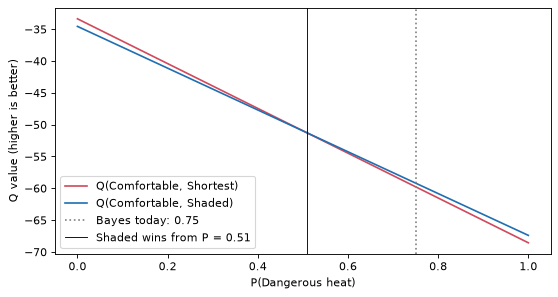

In [20]:
ps = [i / 100 for i in range(101)]
q_short, q_shade = [], []
for p in ps:
    q, _, _ = bellman_update(*build_mdp(routes, p, PROFILE["heat_vulnerability"]), V0)
    q_short.append(q["Comfortable", "Shortest"]); q_shade.append(q["Comfortable", "Shaded"])
switch = next(p for p, a, b in zip(ps, q_short, q_shade) if b > a)

fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
ax.plot(ps, q_short, color="#d1495b", label="Q(Comfortable, Shortest)")
ax.plot(ps, q_shade, color="#1f6fb2", label="Q(Comfortable, Shaded)")
ax.axvline(belief["posterior"], color="grey", linestyle=":", label=f"Bayes today: {belief['posterior']:.2f}")
ax.axvline(switch, color="black", linewidth=0.8, label=f"Shaded wins from P = {switch:.2f}")
ax.set_xlabel("P(Dangerous heat)"); ax.set_ylabel("Q value (higher is better)"); ax.legend()
plt.show()

## 4. All three together

`recommend()` runs the whole pipeline with the functions written above: shade for the moment → A\* twice → Bayes → MDP. The same trip gets different answers when the inputs change.

In [21]:
def recommend(profile_key, when, feels_like=None, start_latlon=AITU, end_latlon=MEGA):
    profile = config.PROFILES[profile_key]
    net = area.set_time(when)                                       # 0. shade at this moment
    s, _ = area.nearest_node(*start_latlon)
    t, _ = area.nearest_node(*end_latlon)
    found = {}
    for action, key in (("Shortest", "shortest"), ("Shaded", "shaded")):   # 1. A*
        result = astar(net.graph, s, t, make_edge_cost(net.graph, profile, config.SUN_WEIGHT[key]))
        found[action] = route_stats(net.graph, result, profile)
    if feels_like is None:                                          # 2. Bayes
        feels_like, _ = weather.feels_like_at(when, *start_latlon)
    p_dangerous = heat_posterior(prior_for_month(when.month), reading_bucket(feels_like))["posterior"]
    q, _, pi = bellman_update(*build_mdp(found, p_dangerous, profile["heat_vulnerability"]), V0)   # 3. MDP
    return {"profile": profile["label"], "time": f"{when:%d %b %H:%M}",
            "feels like": f"{feels_like} degC ({reading_bucket(feels_like)})", "P(Dangerous)": round(p_dangerous, 2),
            "Shortest": f"{found['Shortest']['length_m']:.0f} m, {found['Shortest']['sun_min']:.0f} sun min",
            "Shaded": f"{found['Shaded']['length_m']:.0f} m, {found['Shaded']['sun_min']:.0f} sun min",
            "decision": pi["Comfortable"]}

scenarios = [
    ("wheelchair", WHEN),                                   # hot July afternoon
    ("wheelchair", datetime(2026, 8, 20, 16, 0, tzinfo=config.ASTANA_TZ)),   # cool August day
    ("standard", WHEN),                                     # faster walker, less vulnerable
    ("elderly", WHEN.replace(hour=18)),                     # evening, longer shadows
]
pd.DataFrame([recommend(p, w) for p, w in scenarios])

,profile,time,feels like,P(Dangerous),Shortest,Shaded,decision
0,Wheelchair user,15 Jul 16:00,31.0 degC (hot),0.75,"1560 m, 29 sun min","1657 m, 25 sun min",Shaded
1,Wheelchair user,20 Aug 16:00,17.6 degC (cool),0.03,"1560 m, 29 sun min","1657 m, 25 sun min",Shortest
2,Pedestrian without mobility needs,15 Jul 16:00,31.0 degC (hot),0.75,"1306 m, 16 sun min","1451 m, 14 sun min",Shortest
3,Elderly pedestrian,15 Jul 18:00,27.5 degC (warm),0.23,"1349 m, 22 sun min","1653 m, 16 sun min",Shortest


- **Hot day, wheelchair:** high heat risk and a vulnerable walker → **Shaded**.
- **Cool day:** Bayes gives a low $P(\text{Dangerous})$, so the shade is not worth the extra minutes → **Shortest**.
- **Pedestrian without mobility needs:** walks faster (fewer sun minutes) and is less vulnerable → **Shortest**.
- **Elderly at 18:00:** the reading is only *warm*, and the shade would save little sun → **Shortest**.

## 5. Check: the notebook gives the same numbers as the project code

The web app and the CLI both call `planner.plan_trip()`, which uses `search.py`, `bayes.py` and `mdp.py`. Here we run it for the same trip and compare.

In [22]:
trip = planner.plan_trip(area, AITU, MEGA, WHEN, "wheelchair")
project = {a: trip["routes"][a]["stats"] for a in ACTIONS}
checks = {
    "Shortest: length, m": (routes["Shortest"]["length_m"], project["Shortest"]["length_m"]),
    "Shaded: length, m": (routes["Shaded"]["length_m"], project["Shaded"]["length_m"]),
    "Shaded: sun minutes": (routes["Shaded"]["sun_min"], project["Shaded"]["sun_min"]),
    "A* expanded (Shortest)": (routes["Shortest"]["expanded"], project["Shortest"]["expanded"]),
    "P(Dangerous | reading)": (belief["posterior"], trip["belief"]["posterior"]),
    "Q(Comfortable, Shortest)": (Q["Comfortable", "Shortest"], trip["q"]["Comfortable", "Shortest"]),
    "Q(Comfortable, Shaded)": (Q["Comfortable", "Shaded"], trip["q"]["Comfortable", "Shaded"]),
}
for name, (ours, theirs) in checks.items():
    assert math.isclose(ours, theirs, rel_tol=1e-9), name
assert decision == trip["decision"]
display(pd.DataFrame(checks, index=["this notebook", "project code"]).T)
print(f"All equal. Decision in both: {decision}")

,this notebook,project code
"Shortest: length, m",1560.081,1560.081
"Shaded: length, m",1657.482,1657.482
Shaded: sun minutes,24.722,24.722
A* expanded (Shortest),878.000,878.000
P(Dangerous | reading),0.750,0.750
"Q(Comfortable, Shortest)",-59.763,-59.763
"Q(Comfortable, Shaded)",-59.186,-59.186


All equal. Decision in both: Shaded


## 6. Notes for the defense

- **Why A\* and not Dijkstra?** Both find the same optimal route (checked with `assert` above), but A\* expands fewer nodes (see the table in 1b) because $h$ pulls the search towards the goal.
- **Why is $h$ admissible?** Every edge costs at least its length, and a length is never shorter than a straight line, as long as both are measured in the same projection. The check over all edges is in section 1b.
- **Why two A\* runs?** Changing $w$ changes the cost function. The MDP needs two concrete options to compare.
- **Why Bayes?** The forecast is noisy, and the same reading means more in July than in May. Bayes combines the season (prior) with the reading (likelihood).
- **Why an MDP?** The result of the walk is uncertain: the walker may or may not become heat-stressed. The MDP weighs minutes against that risk and gives a policy for both states. One Bellman update from the terminal values $V_0$ is a one-step look-ahead.
- **Which numbers are assumptions?** All of them are in `config.py`: the priors, the likelihoods, the hazard rates, the vulnerabilities, the −60 penalty and the access multipliers. The barrier reports are simulated, and OSM maps only 45 trees here, so the real shade is probably larger.